**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**12 | Training-Only Class-Weighted Temporal CNN**

![Stage 12 scientific workflow](../../images/12_workflow.svg)

**Objective:** Compare standard and inverse-square-root class-weighted Cross-Entropy for the same temporal CNN while keeping the source windows, participant split, seed, architecture and training duration fixed.

**Dataset:** The HARTH v2.0 Development cohort from Notebooks 10–11: 14,201 bounded windows from 29 participants, excluding S023 and S032.

**Notebook Scope:** Compute loss weights from Train labels only, fit both CNN variants and compare final-epoch Validation and participant-level results. This is a single-split Development ablation, not independent final Test evaluation.

**01. Imports and Reusable Research Utilities**

In [1]:
# %cd /content
# !git clone -q https://github.com/RezaSaadatyar/human-movement-intelligence.git
# %cd /content/human-movement-intelligence

/content
fatal: destination path 'human-movement-intelligence' already exists and is not an empty directory.
/content/human-movement-intelligence


In [2]:
# =================== 01. Imports and Research Environment ====================

# ----------------- 1. Configure the Colab study environment. -----------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------- 2. Import standard-library tools for repository paths. -----------
import sys
from pathlib import Path

# ------------- 3. Import numerical tools for source-data tables. -------------
import numpy as np
import pandas as pd

# --------- 4. Import visualisation utilities for model diagnostics. ----------
import matplotlib.pyplot as plt

# ------------- 5. Import PyTorch for the two CNN configurations. -------------
import torch

# ------------------ 6. Import notebook table display tools. ------------------
from IPython.display import display

# ----------- 7. Import matched classification evaluation metrics. ------------
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# -------- 7. Resolve the repository root without a fixed local path. ---------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent: raise RuntimeError("Open from the project directory.")
    root = root.parent

# ----------- 8. Register reusable project and HARTH module paths. ------------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ---------- 9. Import original HARTH and class-weighting functions. ----------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_window_cohort
from core.data_splitting import split_group_indices
from core.temporal_cnn import train_temporal_cnn, compute_training_class_weights
from core.ml_baselines import classification_class_report, evaluate_predictions_by_subject
from core.group_cross_validation import compare_models_by_subject

# ------------- 12. Apply the standard scientific plotting style. --------------
from core.plot_style import plot_style
plot_style()

# ------------------- 13. Select the PyTorch compute device. -------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type

print("Repository root:", root)
print("Training compute device:", DEVICE)

Compute device and system information
OS: Linux 6.6.122+
CPU: x86_64
Installed RAM: 12.7 GiB
nvidia-smi is not available in this environment.
PyTorch version: 2.11.0+cpu
CUDA is not available to PyTorch; using CPU.
Selected compute device: cpu
Repository root: /content/human-movement-intelligence
Training compute device: cpu


**02. Reconstruct the Bounded Development Window Cohort**

Reuse the 500-window-per-person, label-independent sampling protocol and the same 14,201 windows as Notebooks 10–11. Exclude reserved Test participants before loading and restrict the task to documented activity codes 1–8 after windowing.

In [3]:
# =================== 02. Recreate the Bounded HARTH Cohort ===================

# ---------- 1. Exclude original final Test participant identities. -----------
RESERVED_TEST = {"S023", "S032"}

# ----------------- 2. Reuse all 29 Development participants. -----------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------- 3. Retain the eight documented activity classes. --------------
TASK_CLASSES = tuple(range(1, 9))

# ----------- 4. Build label-pure windows capped at 500 per person. -----------
X, y, metadata, overview = prepare_harth_window_cohort(
    DEVELOPMENT_SUBJECTS, root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, max_windows_per_subject=500,
    window_size=100, step_size=50, sampling_rate=50,
)

# ---------------- 5. Confirm all 29 Development participants. ----------------
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# -------------- 6. Report the observed six-axis signal tensor. ---------------
print("Shared raw IMU windows:", X.shape)

# ---------- 7. Display source and sampling counts per participant. -----------
display(overview[["subject_id", "eligible_windows", "sampled_windows"]])

Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared raw IMU windows: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Preserve Identical Participant-Disjoint Groups**

Keep Train, Validation and unused Development participants unchanged across the two loss conditions.

In [4]:
# =================== 03. Reuse the Subject-Disjoint Split ====================

# ------------ 1. Reproduce the identical Stage 10/11 group split. ------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)

# ------------ 2. Freeze shared Train and Validation row indices. -------------
train_idx, val_idx = parts["train"], parts["validation"]

# ----------- 3. Preserve the same windows for both model variants. -----------
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

# ----------- 4. Identify the original held-out Validation people. ------------
val_subject_ids = metadata.iloc[val_idx]["subject_id"].to_numpy()

# ------------- 5. Require subject-disjoint Train and Validation. -------------
assert not (set(metadata.iloc[train_idx]["subject_id"]) & set(val_subject_ids))

# --------- 6. Report the actual Train and Validation window counts. ----------
print("Train windows:", len(y_train), "Validation windows:", len(y_val))

# ------------ 7. Distinguish unused Development from final Test. -------------
print("Unused development windows:", len(parts["test"]))

Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows
Train windows: 10000 Validation windows: 2701
Unused development windows: 1500


**04. Calculate Train-Only Class Weights**

Derive inverse-square-root weights from Train class counts and normalise them to mean one. Validation frequencies do not determine the weights; the class definitions and source rows remain unchanged.

In [5]:
# ================== 04. Calculate Train-Only Class Weights ===================

# --------------- 1. Count task activity labels in Train only. ----------------
training_counts = pd.Series(y_train).value_counts().reindex(TASK_CLASSES, fill_value=0)

# ------------ 2. Compute inverse-sqrt weights from Train classes. ------------
weights = compute_training_class_weights(y_train, TASK_CLASSES, method="inverse_sqrt")

# ---------- 3. Associate class support with proposed loss weights. -----------
weight_table = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    "train_windows": training_counts.to_numpy(),
    "inverse_sqrt_weight": weights,
})

# -------------- 4. Confirm every class is represented in Train. --------------
assert (training_counts > 0).all()

# ------------- 5. Display observed per-class weight assignments. -------------
display(weight_table.round(4))

,activity,train_windows,inverse_sqrt_weight
0,Walking,2987,0.3973
1,Running,940,0.7083
2,Shuffling,169,1.6704
3,Stairs ascending,156,1.7386
4,Stairs descending,145,1.8034
5,Standing,1502,0.5603
6,Sitting,3240,0.3815
7,Lying,861,0.7401


**05. Train CNNs With Standard and Weighted Loss**

Use the same network architecture, initial seed, DataLoader order, optimiser settings and five-epoch duration. Only the Cross-Entropy class-weight vector differs.

In [6]:
# =================== 05. Train Standard and Weighted CNNs ====================

# ----------- 1. Fix the common seed, model and five-epoch budget. ------------
settings = dict(
    X_train=X_train, y_train=y_train,
    X_validation=X_val, y_validation=y_val,
    classes=TASK_CLASSES, epochs=5, batch_size=128,
    learning_rate=1e-3, seed=42,
    device="cuda" if torch.cuda.is_available() else "cpu",
)

# --------- 2. Prepare independent histories for both loss variants. ----------
runs = {}

# ------------- 3. Train standard and inverse-sqrt-weighted CNNs. -------------
for method, name in [
    ("none", "Standard CNN"),
    ("inverse_sqrt", "Weighted CNN"),
]:
    print("\nTraining:", name)
    model, history, predicted, scaler = train_temporal_cnn(
        **settings, class_weighting=method
    )
    runs[name] = {"model": model, "history": history, "predicted": predicted}
    print("Last-epoch Macro F1:", float(history.iloc[-1]["validation_macro_f1"]))

# ------------ 4. Confirm completion of both model configurations. ------------
assert len(runs) == 2


Training: Standard CNN
Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5911
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5975
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6015
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6263
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6659
Last-epoch Macro F1: 0.6658966288485454

Training: Weighted CNN
Epoch 1/5 | loss=0.9724 | validation Macro F1=0.5933
Epoch 2/5 | loss=0.5297 | validation Macro F1=0.6230
Epoch 3/5 | loss=0.4122 | validation Macro F1=0.6744
Epoch 4/5 | loss=0.3386 | validation Macro F1=0.7334
Epoch 5/5 | loss=0.2894 | validation Macro F1=0.8014
Last-epoch Macro F1: 0.8013824361730992


**06. Compare Training and Validation Results**

Final-epoch Validation Macro F1 was 0.6659 for standard Cross-Entropy and 0.7968 for the weighted variant. Training-loss magnitudes should not be compared directly because the loss functions weight classes differently; improvements may also vary by activity.

,model,macro_f1,balanced_accuracy,validation_windows
0,Standard CNN,0.6659,0.6459,2701
1,Weighted CNN,0.8014,0.8129,2701


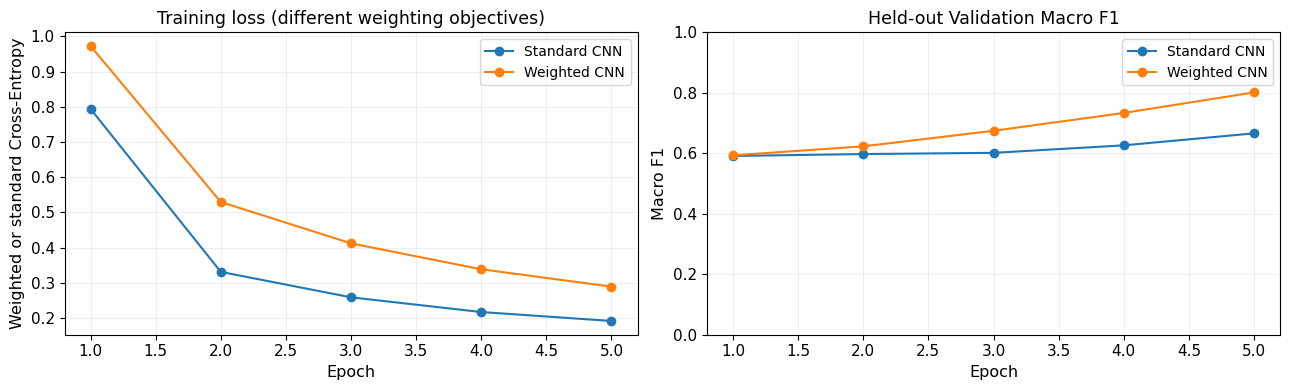

In [7]:
# ================= 06. Compare Validation Curves and Metrics =================

# ----------- 1. Score both variants on the same Validation labels. -----------
summary = pd.DataFrame([
    {"model": name,
     "macro_f1": f1_score(
         y_val, result["predicted"], labels=TASK_CLASSES,
         average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, result["predicted"]),
     "validation_windows": len(y_val)}
    for name, result in runs.items()
])

# ------------ 2. Display Macro F1 and balanced accuracy for both. ------------
display(summary.round(4))

# -------------- 3. Plot loss and Macro F1 over the five epochs. --------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, result in runs.items():
    curve = result["history"]
    axes[0].plot(curve["epoch"], curve["train_loss"], marker="o", label=name)
    axes[1].plot(curve["epoch"], curve["validation_macro_f1"], marker="o", label=name)

axes[0].set(title="Training loss (different weighting objectives)",
            xlabel="Epoch", ylabel="Weighted or standard Cross-Entropy")
axes[1].set(title="Held-out Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

**07. Inspect Minority-Class Errors**

Compare class-level precision, recall, F1 and confusion matrices, with particular attention to Shuffling and stair activities.

,model,class,support,precision,recall,f1
0,Standard CNN,Walking,453,0.8848,0.9492,0.9159
1,Standard CNN,Running,78,0.9873,1.0000,0.9936
2,Standard CNN,Shuffling,15,0.0000,0.0000,0.0000
3,Standard CNN,Stairs ascending,30,1.0000,0.1000,0.1818
4,Standard CNN,Stairs descending,32,1.0000,0.1875,0.3158
5,Standard CNN,Standing,536,0.9348,0.9366,0.9357
6,Standard CNN,Sitting,1363,0.9749,0.9993,0.9870
7,Standard CNN,Lying,194,1.0000,0.9948,0.9974
8,Weighted CNN,Walking,453,0.9664,0.8896,0.9264
9,Weighted CNN,Running,78,1.0000,0.9744,0.9870


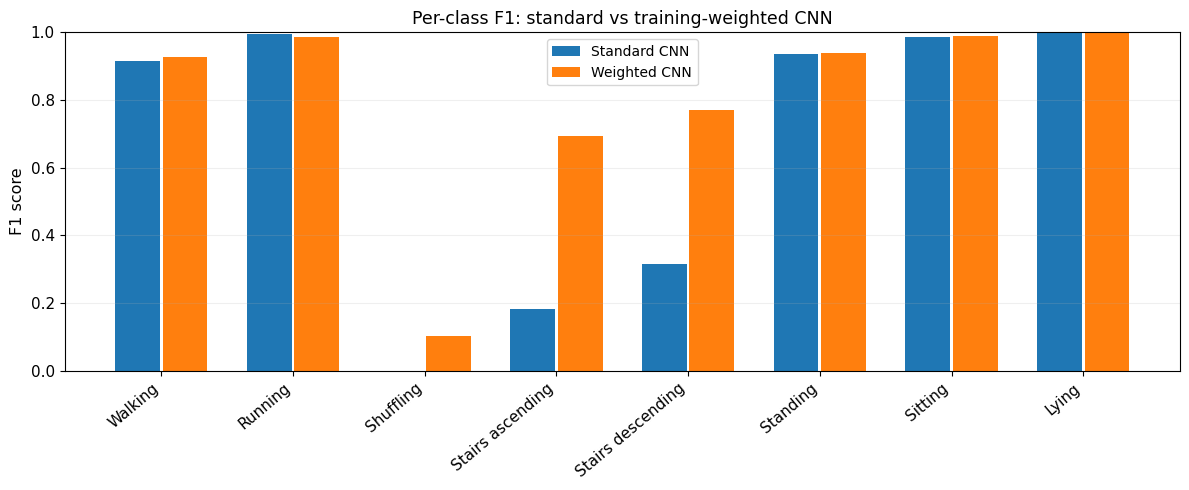

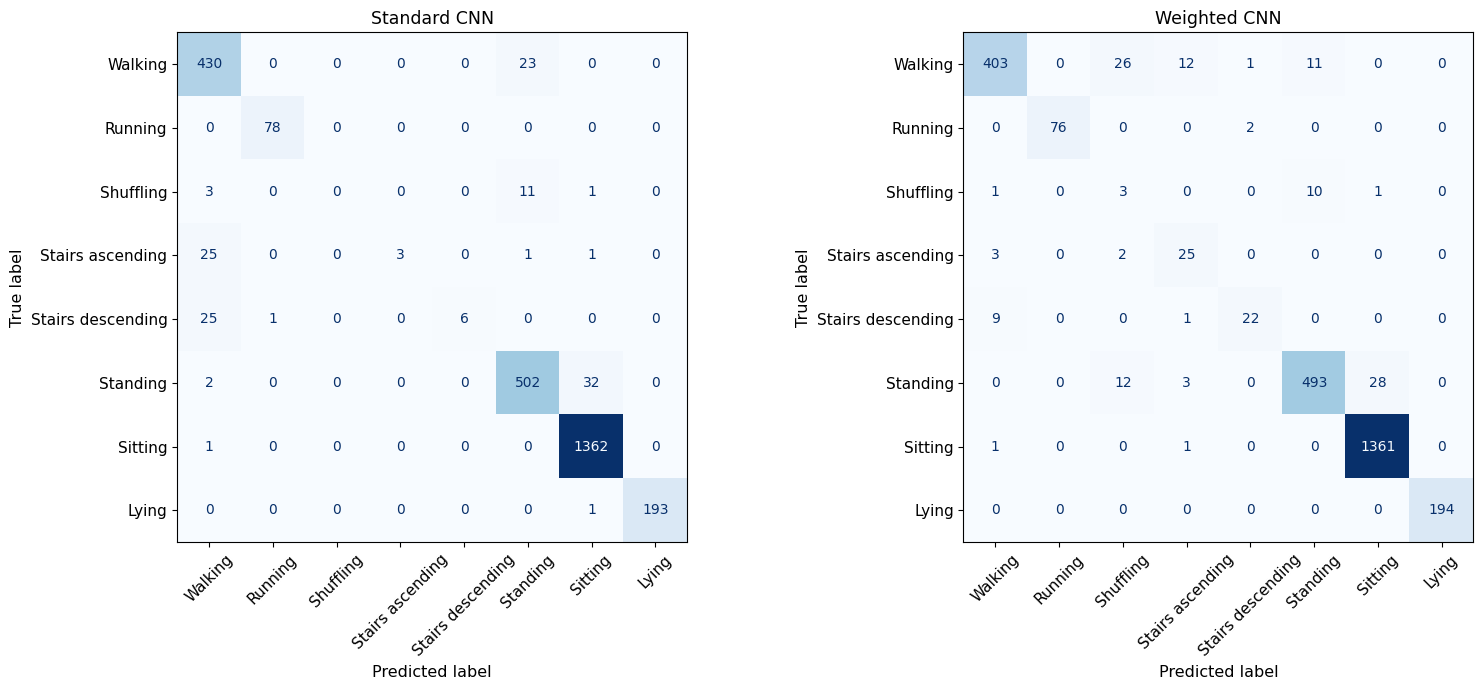

In [8]:
# =============== 07. Inspect Class-Level and Confusion Errors ================

# ------------- 1. Collect eight-class results for both CNN runs. -------------
reports = []

# --------- 2. Evaluate precision, recall, F1 and support per class. ----------
for name, result in runs.items():
    report = classification_class_report(
        y_val, result["predicted"], classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    )
    report["model"] = name
    reports.append(report)

# --------- 3. Align activity results without changing class labels. ----------
class_table = pd.concat(reports, ignore_index=True)

# ---------------- 4. Display class-level Validation metrics. -----------------
display(class_table[["model", "class", "support", "precision", "recall", "f1"]].round(4))

# ---------------- 5. Initialise per-class F1 comparison bars. ----------------
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(TASK_CLASSES))

# ------------- 6. Compare both model variants for each activity. -------------
for i, name in enumerate(runs):
    values = class_table.loc[class_table["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 0.5) * 0.36, values, width=0.34, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES], rotation=40, ha="right")
ax.set(title="Per-class F1: standard vs training-weighted CNN",
       ylabel="F1 score", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

# --------------- 7. Inspect class-specific prediction errors. ----------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (name, result) in zip(axes, runs.items()):
    matrix = confusion_matrix(y_val, result["predicted"], labels=TASK_CLASSES)
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()

**08. Compare Paired Participant-Level Changes**

Calculate fixed-task scores for each Validation participant under both loss conditions. Treat the results as descriptive rather than a statistical significance test.

,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.3297,0.2318,0.0978
1,S012,0.8951,0.5911,0.3040
2,S019,0.8374,0.5911,0.2462
3,S022,0.9012,0.6290,0.2722
4,S036,0.4938,0.5745,-0.0807
5,S037,0.7817,0.7463,0.0354


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,6,0.1458,0.172,5,1,0


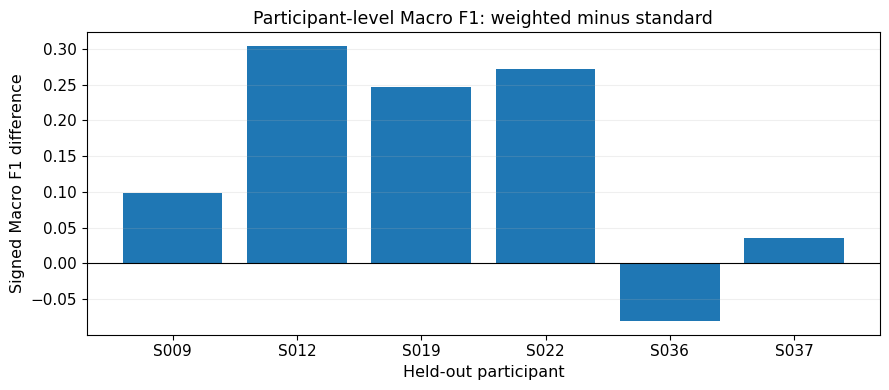

In [9]:
# ================= 08. Compare Matched Held-Out Participants =================

# --------- 1. Compute fixed-task Macro F1 for each held-out person. ----------
individual_results = pd.concat([
    evaluate_predictions_by_subject(
        y_val, result["predicted"], val_subject_ids,
        TASK_CLASSES, model_name=name,
    )
    for name, result in runs.items()
], ignore_index=True)

# ----------- 2. Pair weighted minus standard scores by individual. -----------
paired, paired_summary = compare_models_by_subject(
    individual_results, model_a="Weighted CNN", model_b="Standard CNN",
    score_column="macro_f1_fixed_task",
)

# ----------- 3. Display the signed participant-level differences. ------------
display(paired.round(4))

# ------------- 4. Display the paired participant-level summary. --------------
display(pd.DataFrame([paired_summary]).round(4))

# ------------ 5. Plot one comparison per Validation participant. -------------
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Participant-level Macro F1: weighted minus standard",
       xlabel="Held-out participant", ylabel="Signed Macro F1 difference")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

**09. Scientific Quality Gate and Limitations**

Check shared source rows, group separation, Train-only weighting and complete evaluation outputs. One Development split and seed cannot establish a general class-weighting benefit or replace independent final Test evaluation.

In [10]:
# ================= 09. Scientific Training-Loss Quality Gate =================

# ------------ 1. Check source windows remain aligned with labels. ------------
assert len(X_train) == len(y_train) and len(X_val) == len(y_val)

# ---------------- 2. Require full eight-class Train support. -----------------
assert set(np.unique(y_train)) == set(TASK_CLASSES)

# ---------- 3. Exclude original final Test participant identities. -----------
assert not (set(val_subject_ids) & RESERVED_TEST)

# ----------- 4. Verify both prediction sets match Validation rows. -----------
assert all(len(item["predicted"]) == len(y_val) for item in runs.values())

# ------------- 5. Require one paired score per held-out person. --------------
assert len(paired) == len(set(val_subject_ids))

# ----------- 6. Validate both reported aggregate Macro F1 values. ------------
assert summary["macro_f1"].between(0, 1).all()

# ---------- 7. Report the passed study-specific scientific checks. -----------
print("Training-loss ablation quality gate: PASSED")

# ----------------- 8. Confirm no final Test data were used. ------------------
print("Reserved original Test loaded/scored: NO")

# ------------- 9. State the Development-only evidence boundary. --------------
print("Independent validation of weight benefits: NOT ESTABLISHED")

Training-loss ablation quality gate: PASSED
Reserved original Test loaded/scored: NO
Independent validation of weight benefits: NOT ESTABLISHED
